Seasonal Effect On bcycle Usage In Oslo City

**This assignment is about detecting how seasons effects the usage of bcycles in Oslo City and difference between weekdays and weekends.**

1. (i) Data Source: https://oslobysykkel.no/en/open-data/historical 
*The data is provided according to the Norwegian License for Open Government Data 2.0 NLOD 2.0.

(ii) There are csv files for every month of the previous years up to now. Each has thousands of datas, with information of starting and ending dates of usage of bicycles, so this provides also duration time, stations ids,names,latitude,longitudes where journey started and ended. Descriptions for starting stations and ending stations.

I probably will need to use stations starting end ending points along duration of usage of bicycle,and dates of the journey so that can help to detect usage according the seasons, and distinguish for weekdays and weekends usage diference.

2. I would like to use table firstly to organize datas that I am going to use and display them. Timeseries line could be also useful: Date on the x-axis, daily trip count on the y-axis so this plot can show season effects on the amount of journey. 

3. My aim is to test two things: whether the level of bicycle usage differs significantly across seasons, and whether the weekday–weekend difference is itself constant across seasons or changes with them.The analysis will start with descriptive statistics and visual exploration and time series of daily trips, box plots of daily volume by season and day type. Since the sample is large, I will report effect sizes as well as p-values, and check the model's assumptions with residual diagnostics before drawing conclusions. I may even be able to predict bicycle necessity and amount according season for next year as well.

In [2]:
import glob
import pandas as pd
files = sorted(glob.glob('Datas/2025/*.csv')) # List all CSV files in the Datas/2025 
print(len(files)) # Print the number of CSV files found

12


In [3]:
parts = [] # List to hold the DataFrames for each CSV file
for file in files:
    part = pd.read_csv(file) # Read the CSV file into a DataFrame
    parts.append(part) # Append the DataFrame to the list
df = pd.concat(parts, ignore_index=True) # Concatenate all DataFrames into a single DataFrame
print(df.head()) # Print the first few rows of the combined DataFrame

                         started_at                          ended_at  \
0  2025-01-01 04:37:39.287000+00:00  2025-01-01 04:49:08.139000+00:00   
1  2025-01-01 04:44:32.058000+00:00  2025-01-01 04:51:45.817000+00:00   
2  2025-01-01 05:06:52.481000+00:00  2025-01-01 05:11:28.880000+00:00   
3  2025-01-01 05:22:23.200000+00:00  2025-01-01 05:28:45.298000+00:00   
4  2025-01-01 06:05:12.184000+00:00  2025-01-01 06:08:39.238000+00:00   

   duration  start_station_id     start_station_name  \
0       688               441        Vippetangen øst   
1       433               535       Uranienborgveien   
2       276               521     Jess Carlsens gate   
3       382               480  Helga Helgesens plass   
4       207               507      Jens Bjelkes Gate   

  start_station_description  start_station_latitude  start_station_longitude  \
0           nærmest Operaen               59.903989                10.741077   
1     vest for Slottsparken               59.920042             

In [4]:
df.shape

(1113904, 13)

In [5]:
df["started_at"] = pd.to_datetime(df["started_at"], format="ISO8601") # Convert the 'started_at' column to datetime format
df["ended_at"] = pd.to_datetime(df["ended_at"], format="ISO8601") # Convert the 'ended_at' column to datetime format

In [6]:
df.dtypes

started_at                   datetime64[ns, UTC]
ended_at                     datetime64[ns, UTC]
duration                                   int64
start_station_id                           int64
start_station_name                        object
start_station_description                 object
start_station_latitude                   float64
start_station_longitude                  float64
end_station_id                             int64
end_station_name                          object
end_station_description                   object
end_station_latitude                     float64
end_station_longitude                    float64
dtype: object

In [7]:
df["started_at"] = df["started_at"].dt.tz_convert("Europe/Oslo")
df["ended_at"]   = df["ended_at"].dt.tz_convert("Europe/Oslo")  

In [8]:
# i need to supervise the data to decrease and use only the information i need. 
df = df.drop(columns=["start_station_id", "start_station_name", "end_station_id", "end_station_name","start_station_description","start_station_latitude","start_station_longitude","end_station_description","end_station_latitude","end_station_longitude"]) 
# Drop unnecessary columns

In [9]:
df.columns

Index(['started_at', 'ended_at', 'duration'], dtype='object')

In [10]:
df.dtypes.head(2)

started_at    datetime64[ns, Europe/Oslo]
ended_at      datetime64[ns, Europe/Oslo]
dtype: object

In [11]:
df[df["started_at"].dt.month == 12].head(5)

,started_at,ended_at,duration
1089579,2025-12-01 00:06:28.965000+01:00,2025-12-01 00:17:06.196000+01:00,637
1089580,2025-12-01 00:22:27.269000+01:00,2025-12-01 00:28:07.560000+01:00,340
1089581,2025-12-01 00:36:38.058000+01:00,2025-12-01 00:41:19.958000+01:00,281
1089582,2025-12-01 00:40:02.735000+01:00,2025-12-01 00:42:33.269000+01:00,150
1089583,2025-12-01 00:43:30.106000+01:00,2025-12-01 01:29:08.194000+01:00,2738


In [12]:
df["date"] = df["started_at"].dt.date # Create a new column 'date' with only the date part of 'started_at'

In [13]:
df.shape #tested if new column is added

(1113904, 4)

In [14]:
df.loc[1089579, "date"] 
#testing the date for the row 1089579 which seemed to be in november in UTC Timezone, but it should be in December for Oslo Timezone. The date is correct, it is in December for Oslo Timezone.

datetime.date(2025, 12, 1)

In [15]:
# will add day_type column for weekday and weekend analysis.
import numpy as np
#pandas gives the day of the week as an integer, where Monday is 0 and Sunday is 6.
df["day_type"] = np.where(df["started_at"].dt.dayofweek < 5, "Weekday", "Weekend")
df["day_type"].value_counts() # Check the distribution of weekday and weekend rides

day_type
Weekday    894320
Weekend    219584
Name: count, dtype: int64

In [16]:
df.groupby("day_type")["date"].nunique() # Count the number of unique dates for each day type (Weekday vs Weekend)

day_type
Weekday    261
Weekend    104
Name: date, dtype: int64

in this result it seems during weekdays there are more bcycle usage than weekends. 
weekday average per day: 894320/261= 3426.51
weekend average per day: 219584/104= 2111.38

comparison between weekdays and weekend: 3426.51/2111.38= 1.62
Note: In Oslo bcycle usage per weekday is 62% more than per weekend.
The raw total ratio (894,320 / 219,584 ≈ 4.07) is misleading, because 2025 has 2.5 times more weekdays than weekend days.

In [17]:
# i need to add season column to the data to analyze the data by season.
# Winter: December, January, February are 12,1,2 
# Spring: March, April, May are 3,4,5
# Summer: June, July, August are 6,7,8
# Autumn: September, October, November are 9,10,11

season_map={12: "Winter", 1: "Winter", 2: "Winter",
            3: "Spring", 4: "Spring", 5: "Spring",
            6: "Summer", 7: "Summer", 8: "Summer",
            9: "Autumn", 10: "Autumn", 11: "Autumn"}
df["season"] = df["started_at"].dt.month.map(season_map)
df["season"].value_counts() # Check the distribution of rides across seasons

season
Summer    471161
Autumn    308028
Spring    284564
Winter     50151
Name: count, dtype: int64

In [18]:
df.groupby("season")["date"].nunique() # Count the number of unique dates for each season

season
Autumn    91
Spring    92
Summer    92
Winter    90
Name: date, dtype: int64

In [19]:
df["season"].isna().sum()

np.int64(0)

In [20]:
daily = df.groupby(["date","day_type","season"]).size().reset_index(name="ride_count") # Group by date and calculate the count of rides


In [21]:
print(daily.shape) # Print the shape of the daily aggregated DataFrame

(365, 4)


In [22]:
print(daily ["ride_count"].sum()) # Print the total count of rides

1113904


In [23]:
print(daily["date"].duplicated().sum())

0


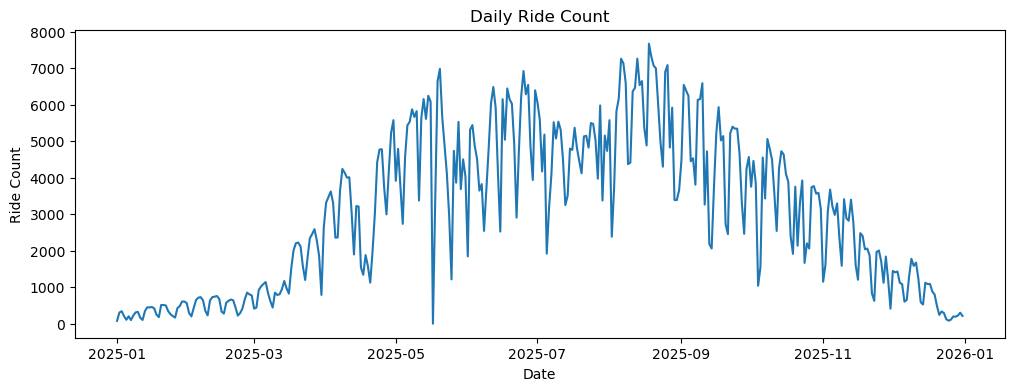

In [24]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 4))
plt.plot(daily["date"], daily["ride_count"])
plt.xlabel("Date")
plt.ylabel("Ride Count")
plt.title("Daily Ride Count")
plt.show()


Season Effect: Winter low, summer season bicycle rides are higher especially August is peak month.
   - 17 May: National holiday probably because of that its strange, only 4 usage detected. I will investigate it below more detailly.
   
   - Weekly pattern: the regular short-term ups and downs come from the weekday vs weekend difference


   

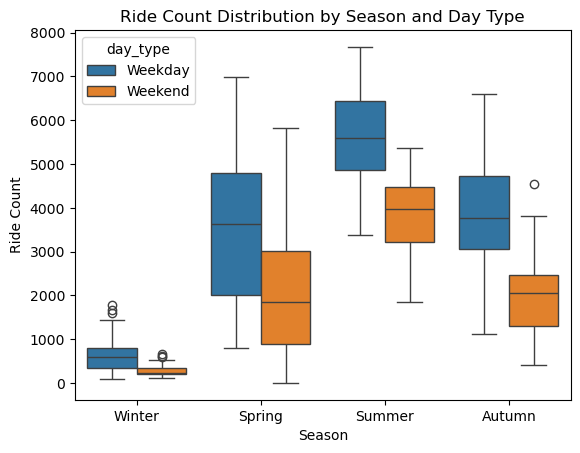

In [25]:
import seaborn as sns
order = ["Winter", "Spring", "Summer", "Autumn"]
sns.boxplot(data=daily, x="season", y="ride_count", hue="day_type", order=order)
plt.title("Ride Count Distribution by Season and Day Type")
plt.xlabel("Season")
plt.ylabel("Ride Count")
plt.show()

In [26]:
 # Group by season and day type, and calculate the average ride count
#i will use pandas groupby which is method for the dataframe to group the data by one or 
# more columns and perform aggregate functions on the grouped data. In this case, I will group 
# the daily DataFrame by season and day type, and then calculate the mean of the ride count for each group. 
# The result will be a new DataFrame that shows the average ride count for each combination of season and day type.
my_group = daily.groupby(["season", "day_type"])["ride_count"].agg(["mean","median", "std", "min", "max","count"])
my_group = my_group.reindex(order, level="season") 
my_group = my_group.round(0) # Round the values to 0 decimal places
my_group


mean  median     std   min   max  count
season day_type                                           
Winter Weekday    651.0   595.0   408.0    83  1783     66
       Weekend    299.0   239.0   159.0   108   655     24
Spring Weekday   3522.0  3640.0  1763.0   790  6983     65
       Weekend   2059.0  1858.0  1414.0     4  5826     27
Summer Weekday   5658.0  5595.0  1044.0  3378  7672     65
       Weekend   3828.0  3976.0   982.0  1848  5361     27
Autumn Weekday   3917.0  3773.0  1343.0  1125  6591     65
       Weekend   2056.0  2064.0   995.0   415  4536     26

### Questions on the descriptive table
`my_group` is rounded for display only, so the calculations below use the unrounded values from `daily`.

In [27]:
# (a) Weekday / weekend gap per season, computed from unrounded means
means = daily.groupby(["season", "day_type"])["ride_count"].mean().unstack().reindex(order)
means["difference"] = means["Weekday"] - means["Weekend"] # absolute gap (rides per day)
means["ratio"] = means["Weekday"] / means["Weekend"] # relative gap
means.round(2)

day_type,Weekday,Weekend,difference,ratio
season,,,,
Winter,651.20,298.83,352.36,2.18
Spring,3522.46,2059.41,1463.05,1.71
Summer,5658.48,3828.15,1830.33,1.48
Autumn,3916.62,2055.69,1860.92,1.91


**(a) Weekday / weekend ratio.** Weekdays are busier than weekends in every season, but the size of the gap depends on how it is measured:
- **Ratio:** largest in Winter (2.18), smallest in Summer (1.48). Spring is 1.71, Autumn 1.91.
- **Absolute difference:** smallest in Winter (about 352 rides per day), largest in Summer and Autumn (about 1830 to 1860 rides per day).

So the answer to "does the weekday/weekend gap change with the season?" depends on the scale. On the raw scale the gap grows with the overall level. On the ratio scale it shrinks in Summer, because leisure trips on summer weekends partly replace the missing commuter trips.

A log model measures effects as ratios, so this suggests the season × day_type interaction should be tested on the log scale (Model 1).

In [28]:
# (b) Does the spread grow with the level?
spread = daily.groupby(["season", "day_type"])["ride_count"].agg(["mean", "std"]).reindex(order, level="season")
spread["cv"] = spread["std"] / spread["mean"] # coefficient of variation = relative spread
print(spread.round(2))
print("Correlation between group mean and group std:", round(spread["mean"].corr(spread["std"]), 2))
print("Largest std / smallest std:", round(spread["std"].max() / spread["std"].min(), 1))

                    mean      std    cv
season day_type                        
Winter Weekday    651.20   408.15  0.63
       Weekend    298.83   158.90  0.53
Spring Weekday   3522.46  1763.12  0.50
       Weekend   2059.41  1414.20  0.69
Summer Weekday   5658.48  1043.54  0.18
       Weekend   3828.15   982.24  0.26
Autumn Weekday   3916.62  1342.84  0.34
       Weekend   2055.69   994.62  0.48
Correlation between group mean and group std: 0.62
Largest std / smallest std: 11.1


**(b) Std versus mean.** In general the std grows with the mean: the correlation between group means and group stds is 0.62. Winter groups have a std of about 160 to 410, while the other groups have about 980 to 1760. The relationship is not perfect, though. Spring has a larger std than Summer even though its mean is lower, because Spring covers the steep rise from March (about 1600 rides per weekday) to May (about 5300).

**Meaning for OLS / ANOVA.** These models assume **equal variance** (homoscedasticity) in every group. Here the largest std is about 11 times the smallest, so the variances differ by a factor of more than 100. A common rule of thumb allows a factor of about 4. The assumption is clearly violated on the raw scale, which makes p-values and confidence intervals from a raw OLS unreliable.

When the std is roughly proportional to the mean, a **log transform** stabilises the variance. The relative spread (coefficient of variation, `cv`) varies much less than the std, so `log(ride_count)` is the natural next step. Because the `cv` is not completely constant (0.18 to 0.69), the residuals of the log model still need to be checked.

In [29]:
# (c) Which group has the largest gap between mean and median?
center = daily.groupby(["season", "day_type"])["ride_count"].agg(["mean", "median"]).reindex(order, level="season")
center["mean_minus_median"] = center["mean"] - center["median"]
print(center.round(1))

# Spring weekend with and without 17 May (4 rides)
spring_we = daily[(daily["season"] == "Spring") & (daily["day_type"] == "Weekend")]["ride_count"]
print("Spring weekend mean, all days:     ", round(spring_we.mean(), 1))
print("Spring weekend mean, without 17 May:", round(spring_we[spring_we > 4].mean(), 1))

# Spring split by month
spring = daily[daily["season"] == "Spring"].copy()
spring["month"] = pd.to_datetime(spring["date"]).dt.month
spring.groupby(["month", "day_type"])["ride_count"].mean().unstack().round(0)

                   mean  median  mean_minus_median
season day_type                                   
Winter Weekday    651.2   595.0               56.2
       Weekend    298.8   239.0               59.8
Spring Weekday   3522.5  3640.0             -117.5
       Weekend   2059.4  1858.0              201.4
Summer Weekday   5658.5  5595.0               63.5
       Weekend   3828.1  3976.0             -147.9
Autumn Weekday   3916.6  3773.0              143.6
       Weekend   2055.7  2063.5               -7.8
Spring weekend mean, all days:      2059.4
Spring weekend mean, without 17 May: 2138.5


day_type,Weekday,Weekend
month,,
3,1611.0,916.0
4,3590.0,2390.0
5,5280.0,3036.0


**(c) Largest mean–median gap.** The largest gap is in **Spring weekend**: the mean (2059) is about 201 rides above the median (1858).

**17 May is not the cause.** With only 4 rides it pulls the mean *down*. Without it the mean rises to about 2138, which makes the gap even larger. 17 May does inflate the std and is a clear outlier, so it still needs a decision before Model 1.

**The real cause is that Spring mixes three very different months.** Weekend averages are about 916 in March, 2390 in April and 3036 in May. Most weekend days sit in the lower and middle part of that range, while a smaller number of busy May weekends form a long right tail that pulls the mean above the median. Season is therefore a coarse variable: it hides a strong trend *inside* the season. Weather and temperature (planned extension) should explain much of this.

Summer weekend shows the opposite sign (mean about 148 below the median). A few unusually low days, probably rainy days or holidays, pull the mean down.

### Interpretation of the box plot and the table
- **Season effect:** Daily usage rises sharply from Winter to Summer and falls again in Autumn. A Summer weekday averages about 5660 rides, a Winter weekday about 650, roughly 9 times more. The boxes for Winter barely overlap with the other seasons, so the season effect is large.
- **Day type effect:** In every season, weekdays have more rides than weekends (ratio 1.48 to 2.18), which points to commuting as a main use of city bikes.
- **Interaction:** The weekday/weekend ratio is not constant across seasons (largest in Winter, smallest in Summer). Whether this is a real interaction will be tested with a two-way model on the log scale.
- **Spread:** The boxes get taller as the level rises, and Spring has the widest boxes because it covers March to May. This unequal variance is why the model will use `log(ride_count)` instead of the raw counts.
- **Outliers:** 17 May (4 rides, national day) is the extreme low point in Spring weekend and must be handled (dropped with justification, or a holiday dummy) before modelling.
- **Medians versus means:** The mean and median are close in most groups (within about 150 rides), so the group means describe the typical day reasonably well. Spring weekend is the exception (see c).

In [30]:
daily.to_csv("daily_2025.csv", index=False) # Save the daily aggregated DataFrame to a CSV file